In [1]:
#%%R
# myDF <- read.csv("/anvil/projects/tdm/data/flights/subset/2007.csv")

In [2]:
#%%R Specifying the R Kernel
library(data.table) # Importing the data.table library
myDF <- fread("/anvil/projects/tdm/data/flights/subset/2007.csv") # Specifying "myDF" as the dataset, but using the fread function
head(myDF) # Shows top results
dim(myDF) # Shows dimensions (7 mil rows, 29 columns)

Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,ArrTime,CRSArrTime,UniqueCarrier,FlightNum,...,TaxiIn,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<chr>,<int>,...,<int>,<int>,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>
2007,1,1,1,1232,1225,1341,1340,WN,2891,...,4,11,0,,0,0,0,0,0,0
2007,1,1,1,1918,1905,2043,2035,WN,462,...,5,6,0,,0,0,0,0,0,0
2007,1,1,1,2206,2130,2334,2300,WN,1229,...,6,9,0,,0,3,0,0,0,31
2007,1,1,1,1230,1200,1356,1330,WN,1355,...,3,8,0,,0,23,0,0,0,3
2007,1,1,1,831,830,957,1000,WN,2278,...,3,9,0,,0,0,0,0,0,0
2007,1,1,1,1430,1420,1553,1550,WN,2386,...,2,7,0,,0,0,0,0,0,0


[1] 7453215      29

In [3]:
options(repr.matrix.max.cols=50) # Shows all the columns in the dataset

In [4]:
head(myDF)

Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,ArrTime,CRSArrTime,UniqueCarrier,FlightNum,TailNum,ActualElapsedTime,CRSElapsedTime,AirTime,ArrDelay,DepDelay,Origin,Dest,Distance,TaxiIn,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<chr>,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>
2007,1,1,1,1232,1225,1341,1340,WN,2891,N351,69,75,54,1,7,SMF,ONT,389,4,11,0,,0,0,0,0,0,0
2007,1,1,1,1918,1905,2043,2035,WN,462,N370,85,90,74,8,13,SMF,PDX,479,5,6,0,,0,0,0,0,0,0
2007,1,1,1,2206,2130,2334,2300,WN,1229,N685,88,90,73,34,36,SMF,PDX,479,6,9,0,,0,3,0,0,0,31
2007,1,1,1,1230,1200,1356,1330,WN,1355,N364,86,90,75,26,30,SMF,PDX,479,3,8,0,,0,23,0,0,0,3
2007,1,1,1,831,830,957,1000,WN,2278,N480,86,90,74,-3,1,SMF,PDX,479,3,9,0,,0,0,0,0,0,0
2007,1,1,1,1430,1420,1553,1550,WN,2386,N611SW,83,90,74,3,10,SMF,PDX,479,2,7,0,,0,0,0,0,0,0


In [5]:
head(myDF$Origin) # Shows the origin of the top 5 results
head(myDF$Distance) # Shows the distance of the top 5 results
head(myDF$Distance,n=20) # Shows the distance of the top 20 results

[1] "SMF" "SMF" "SMF" "SMF" "SMF" "SMF"

[1] 389 479 479 479 479 479

[1] 389 479 479 479 479 479 647 647 647 647 647 647 480 480 480 480 480 480 480
[20] 480

In [6]:
table(myDF$Origin) # Good for wrapping results into a table - in this case, it sorts by origin and its count
# so, for example, ABE 5701 suggests there are that many instances of flights that originated from said place


   ABE    ABI    ABQ    ABY    ACK    ACT    ACV    ACY    ADK    ADQ    AEX 
  5701   2836  41161   1312    314   2349   3872    735    103    691   2996 
   AGS    AKN    ALB    ALO    AMA    ANC    APF    ASE    ATL    ATW    AUS 
  2286    235  14965    300   7542  19755    555   5305 413851   6179  51560 
   AVL    AVP    AZO    BDL    BET    BFL    BGM    BGR    BHM    BIL    BIS 
  3773   2890   5121  32627   1044   5195    966   4091  23535   4694   3155 
   BJI    BLI    BMI    BNA    BOI    BOS    BPT    BQK    BQN    BRO    BRW 
   128    588   4219  61070  18106 128320    364    993   1370   1593    726 
   BTM    BTR    BTV    BUF    BUR    BWI    BZN    CAE    CAK    CDV    CEC 
   819  10347   7239  26687  33019 109385   5237  10660   9335    726   1055 
   CHA    CHO    CHS    CIC    CID    CLD    CLE    CLL    CLT    CMH    CMI 
  4533   1386  15673   1374  11151   2730  78288   1785 127108  38544   2757 
   CMX    COD    COS    CPR    CRP    CRW    CSG    CVG    CWA 

In [7]:
sort(table(myDF$Origin)) # Adding sort to the previous function creates a more organized look, sorted by number of flights


   MKC    GLH    PIR    ISO    EAU    GST    ADK    BJI    MTH    DLG    LWB 
     1      2      4      9     72     90    103    128    128    175    187 
   SOP    TEX    INL    RHI    AKN    ROW    WYS    HTS    ALO    CMX    ACK 
   195    216    218    223    235    235    266    279    300    309    314 
   BPT    PMD    SLE    YKM    ILG    STX    PLN    SUX    APF    BLI    EWN 
   364    392    398    410    455    479    512    534    555    588    601 
   TUP    FLO    SCE    MEI    ADQ    RFD    LWS    BRW    CDV    PSG    SCC 
   603    655    677    678    691    694    706    726    726    726    726 
   WRG    YAK    ACY    TTN    BTM    LYH    BGM    IYK    MCN    BQK    HHH 
   726    726    735    808    819    877    966    981    992    993    997 
   PSE    GTR    BET    EYW    CEC    VLD    MQT    MOT    OTZ    OME    GGG 
  1001   1006   1044   1052   1055   1057   1069   1080   1086   1088   1093 
   OAJ    LCH    ELM    TRI    TXK    GFK    GUC    IPL    ABY 

In [8]:
tail(sort(table(myDF$Origin))) # The tail function can be applied here too (this is super cool)


   PHX    LAX    DEN    DFW    ORD    ATL 
211072 237597 240928 297345 375784 413851 

In [9]:
tail(sort(table(myDF$Origin)),n=10) # This means you can also specify how many number of results you want


   MSP    DTW    LAS    IAH    PHX    LAX    DEN    DFW    ORD    ATL 
155846 177478 183668 200420 211072 237597 240928 297345 375784 413851 

THIS PART BELOW IS NEW CONTENT FOR Q5

Warning message in dotchart(tail(sort(table(myDF$Origin)), n = 10)):
"'x' is neither a vector nor a matrix: using as.numeric(x)"


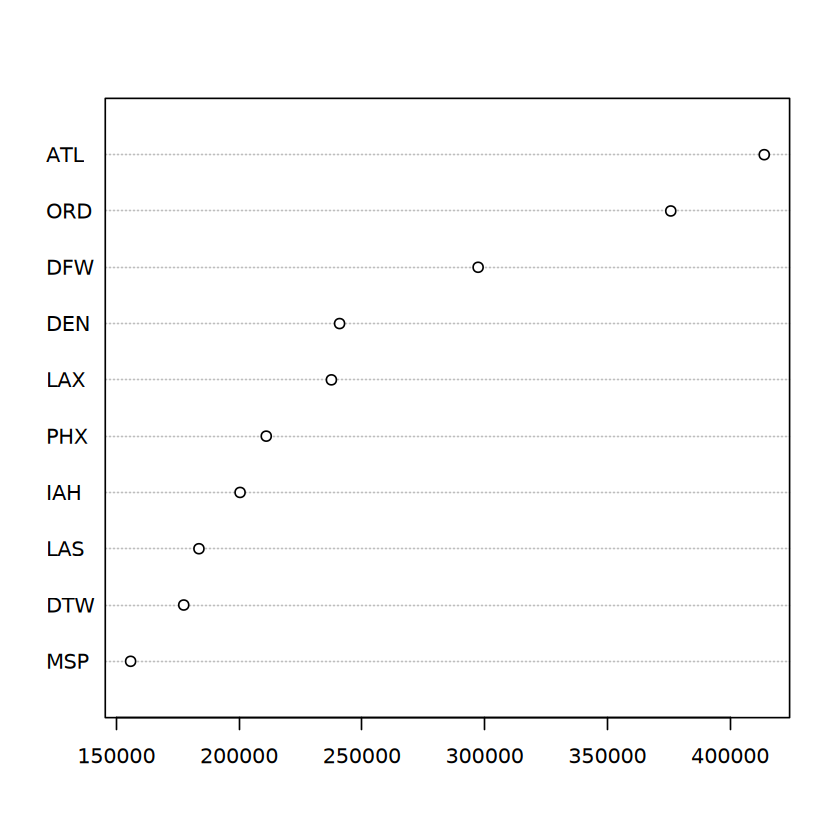

In [11]:
dotchart(tail(sort(table(myDF$Origin)),n=10)) #R is a very stackable coding language in my observation so far
# adding a dotchart at the start is able to (as the name suggests) a dot chart for the data synthesized above